# Team rating systems for NCAA D1 soccer

Goal: estimate the skill gap between two opponents. Each model produces a **rating gap** (home minus away,
home advantage included) that is mapped to **W/D/L probabilities** (ordered logit) and an **expected goal difference** (linear),
so every method is scored identically.

| Family | Models | Idea |
|---|---|---|
| Elo | `elo_none`, `elo_sqrt`, `elo_wfe_autocorr`, `elo_xg` | logistic expectation; margin-of-victory scaling; xG-blended result |
| Pi-ratings | `pi` | separate home/away ratings updated on goal-difference error |
| Glicko | `glicko` | rating + uncertainty, inflating with idle time and at season boundaries |
| Dixon-Coles | `dixon_coles`, `dixon_coles_xg` | time-decayed Poisson attack/defence (goals, or goals/xG blend) |
| Ridge | `ridge_gd`, `ridge_gd_xg` | batch weighted ridge on goal difference |
| Ensemble | `ensemble_ols` | OLS stack of all gaps (fit on training seasons only) |

**Protocol:** walk-forward (rate before each match, then update, no look-ahead). First season = burn-in; mapper and ensemble fit on
training seasons; hyperparameters tuned on the last pre-test season (`python -m ratings.tune`); the final season is held-out test.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "ratings":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dotenv import load_dotenv
load_dotenv(ROOT / ".env")

from ratings.data import load_matches
from ratings.evaluate import evaluate, default_models
from ratings.tune import PARAMS_PATH
from ratings.matchup import fit_final, rankings, predict_matchup, team_names
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)

## 1. Data

In [2]:
matches = {g: load_matches(g) for g in ("male", "female")}
for g, df in matches.items():
    print(g, len(df), "matches;", "xG coverage", f"{df['hxg'].notna().mean():.0%}")
    display(df.groupby("year").agg(matches=("match_id", "count"), teams=("home", "nunique"),
            home_win=("hg", lambda s: np.nan), xg_cov=("hxg", lambda s: s.notna().mean())).drop(columns="home_win").round(2).T)
for g, df in matches.items():
    gd = df.hg - df.ag
    print(g, f"home win {np.mean(gd>0):.1%}  draw {np.mean(gd==0):.1%}  away win {np.mean(gd<0):.1%}  mean GD {gd.mean():.2f}")

male 13358 matches; xG coverage 87%


year,2017,2019,2020,2021,2022,2023,2024,2025,2026
matches,47.00,1025.00,114.00,2780.00,1944.00,1938.00,1971.00,1960.00,1579.00
teams,36.00,206.00,35.00,214.00,214.00,214.00,215.00,216.00,213.00
xg_cov,0.72,0.07,0.82,0.92,0.94,0.94,0.95,0.96,0.96


female 21568 matches; xG coverage 85%


year,2019,2020,2021,2022,2023,2024,2025,2026
matches,675.00,326.00,4483.0,3136.00,3348.00,3380.00,3440.00,2780.00
teams,128.00,77.00,353.0,350.00,359.00,352.00,361.00,354.00
xg_cov,0.13,0.77,0.7,0.89,0.94,0.95,0.91,0.91


male home win 48.7%  draw 21.7%  away win 29.7%  mean GD 0.51
female home win 48.1%  draw 20.5%  away win 31.4%  mean GD 0.51


## 2. Tuned hyperparameters (validation = last pre-test season)

In [3]:
best = json.loads(PARAMS_PATH.read_text())
for g in best:
    print(g)
    display(pd.DataFrame({m: {**v["params"], "val_log_loss": round(v["val_log_loss"], 4)} for m, v in best[g].items()}).T)

male


,k,hfa,carry,val_log_loss,xg_weight,xg_c,lam,gamma,c,c_week,season_c,rd_max,half_life_days,ridge
elo_none,60.0,70.0,1.0,0.9708,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
elo_sqrt,60.0,70.0,0.9,0.9661,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
elo_wfe_autocorr,40.0,70.0,1.0,0.9663,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
elo_xg,60.0,70.0,1.0,0.9572,0.5,1.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pi,NaN,NaN,0.8,0.9735,NaN,NaN,0.1,0.8,3.0,NaN,NaN,NaN,NaN,NaN
glicko,NaN,60.0,0.9,0.9676,NaN,NaN,NaN,NaN,NaN,2.0,120.0,200.0,NaN,NaN
dixon_coles,NaN,NaN,NaN,0.9692,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,180.0,0.5
dixon_coles_xg,NaN,NaN,NaN,0.9623,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,180.0,0.5
ridge_gd,NaN,NaN,NaN,0.9696,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,180.0,2.0
ridge_gd_xg,NaN,NaN,NaN,0.9695,0.5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,365.0,2.0


female


,k,hfa,carry,val_log_loss,xg_weight,xg_c,lam,gamma,c,c_week,season_c,rd_max,half_life_days,ridge
elo_none,80.0,50.0,1.00,0.9309,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
elo_sqrt,80.0,70.0,1.00,0.9238,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
elo_wfe_autocorr,60.0,50.0,1.00,0.9252,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
elo_xg,60.0,30.0,0.90,0.9135,0.25,0.6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
pi,NaN,NaN,0.95,0.9259,NaN,NaN,0.1,0.5,5.0,NaN,NaN,NaN,NaN,NaN
glicko,NaN,40.0,0.90,0.9216,NaN,NaN,NaN,NaN,NaN,2.0,120.0,300.0,NaN,NaN
dixon_coles,NaN,NaN,NaN,0.9139,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,365.0,0.5
dixon_coles_xg,NaN,NaN,NaN,0.9059,0.50,NaN,NaN,NaN,NaN,NaN,NaN,NaN,180.0,0.5
ridge_gd,NaN,NaN,NaN,0.9192,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,365.0,2.0
ridge_gd_xg,NaN,NaN,NaN,0.9104,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,365.0,2.0


## 3. Held-out test performance

In [4]:
results = {}
for g in ("male", "female"):
    res = evaluate(matches[g], default_models(g), return_preds=True)
    results[g] = res
    print(f"== {g}  (test seasons {res[3]}) ==")
    display(res[0].round(4))

== male  (test seasons [np.int32(2026)]) ==


,n,log_loss,rps,brier,accuracy,gd_mae,gd_rmse,xgd_mae
model,,,,,,,,
ensemble_ols,1579,0.9375,0.1902,0.5536,0.5643,1.3663,1.8325,0.9965
dixon_coles_xg,1579,0.9420,0.1915,0.5565,0.5687,1.3774,1.8422,1.0016
elo_xg,1579,0.9460,0.1926,0.5590,0.5668,1.3962,1.8947,1.0287
ridge_gd_xg,1579,0.9465,0.1933,0.5597,0.5522,1.3857,1.8609,1.0171
dixon_coles,1579,0.9547,0.1954,0.5650,0.5617,1.3967,1.8630,1.0262
ridge_gd,1579,0.9609,0.1975,0.5695,0.5529,1.4180,1.8937,1.0421
elo_wfe_autocorr,1579,0.9619,0.1977,0.5700,0.5478,1.4249,1.9149,1.0570
glicko,1579,0.9630,0.1983,0.5707,0.5560,1.4173,1.9090,1.0567
elo_sqrt,1579,0.9651,0.1987,0.5722,0.5472,1.4265,1.9121,1.0618


== female  (test seasons [np.int32(2026)]) ==


,n,log_loss,rps,brier,accuracy,gd_mae,gd_rmse,xgd_mae
model,,,,,,,,
ensemble_ols,2780,0.8879,0.1780,0.5204,0.6058,1.3887,1.9029,1.0228
dixon_coles_xg,2780,0.8893,0.1783,0.5210,0.6061,1.3956,1.9137,1.0382
elo_xg,2780,0.8939,0.1800,0.5244,0.5971,1.4232,1.9928,1.0673
ridge_gd,2780,0.8940,0.1802,0.5248,0.5917,1.4146,1.9486,1.0570
dixon_coles,2780,0.8952,0.1801,0.5249,0.5978,1.4129,1.9369,1.0625
glicko,2780,0.8982,0.1814,0.5270,0.5849,1.4390,2.0269,1.0909
elo_sqrt,2780,0.8999,0.1817,0.5282,0.5878,1.4460,2.0148,1.0971
pi,2780,0.9001,0.1820,0.5280,0.5917,1.4286,1.9820,1.0815
ridge_gd_xg,2780,0.9001,0.1822,0.5291,0.5896,1.4240,1.9570,1.0437


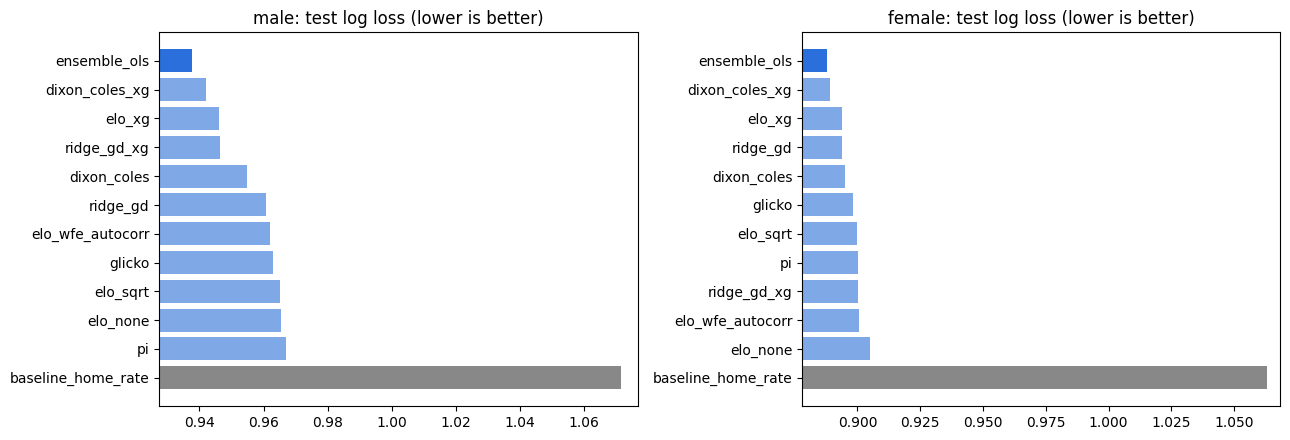

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=False)
for ax, g in zip(axes, results):
    t = results[g][0]["log_loss"].sort_values(ascending=False)
    ax.barh(t.index, t.values, color=["#888" if i == "baseline_home_rate" else "#2a6fdb" if i == "ensemble_ols" else "#7fa8e6" for i in t.index])
    ax.set_xlim(t.min() - 0.01, t.max() + 0.005); ax.set_title(f"{g}: test log loss (lower is better)")
plt.tight_layout(); plt.show()

### Calibration of predicted home-win probability (best model vs plain Elo)

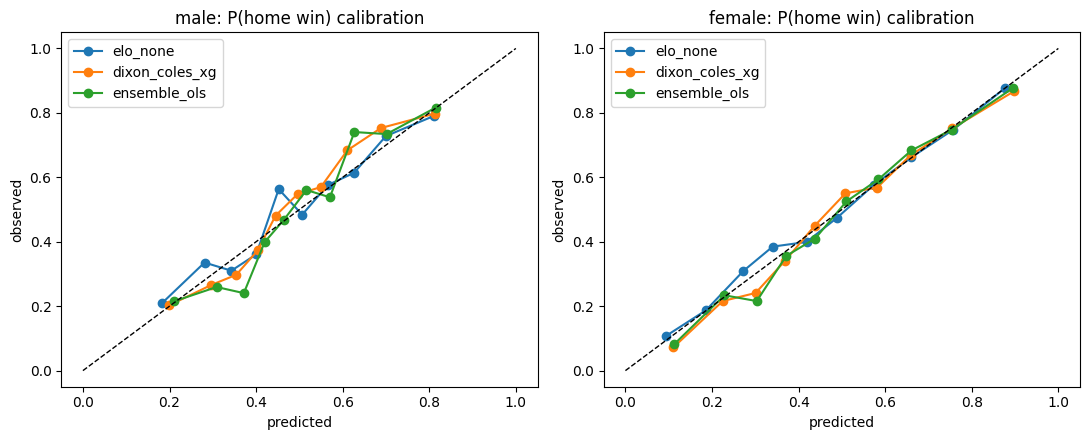

In [6]:
def calib(ax, df, mapper, label, bins=10):
    p = mapper.probs(df["gap"].values)[:, 0]
    y = (df.hg > df.ag).values
    q = pd.qcut(p, bins, duplicates="drop")
    g = pd.DataFrame({"p": p, "y": y}).groupby(q, observed=True).mean()
    ax.plot(g.p, g.y, "o-", label=label)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, g in zip(axes, results):
    table, preds, mappers, test_y = results[g]
    best_name = table.index[0] if table.index[0] != "ensemble_ols" else table.index[1]
    for name in ("elo_none", best_name, "ensemble_ols"):
        df = preds[name]; df = df[df.year.isin(test_y)]
        calib(ax, df, mappers[name], name)
    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_title(f"{g}: P(home win) calibration")
    ax.set_xlabel("predicted"); ax.set_ylabel("observed"); ax.legend()
plt.tight_layout(); plt.show()

### Does the rating gap track real goal difference?

C:\Users\zcoch\AppData\Local\Temp\ipykernel_48000\4001689402.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  b["actual_gd"] = df.groupby("bin", observed=True).apply(lambda x: (x.hg - x.ag).mean())
C:\Users\zcoch\AppData\Local\Temp\ipykernel_48000\4001689402.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  b["actual_gd"] = df.groupby("bin", observed=True).apply(lambda x: (x.hg - x.ag).mean())


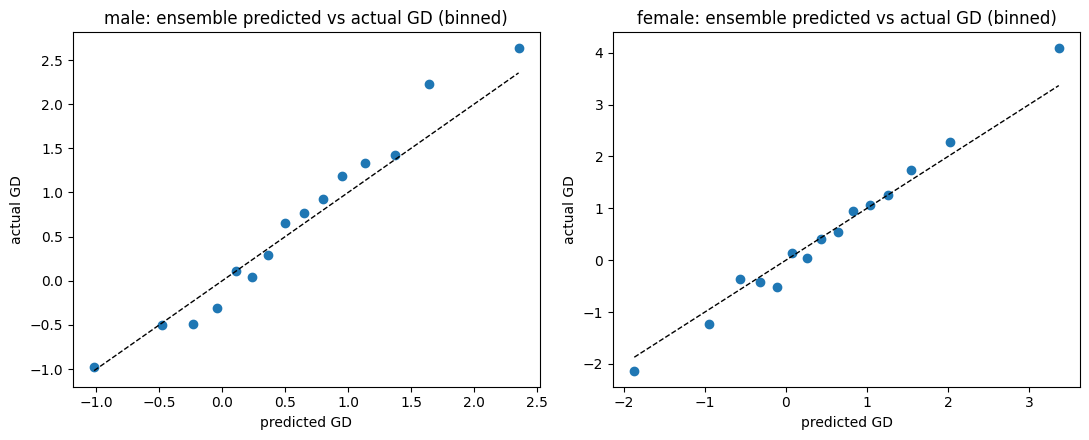

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, g in zip(axes, results):
    table, preds, mappers, test_y = results[g]
    df = preds["ensemble_ols"]; df = df[df.year.isin(test_y)].copy()
    df["bin"] = pd.qcut(df["gap"], 15, duplicates="drop")
    b = df.groupby("bin", observed=True).agg(pred=("gap", "mean"), gd=("hg", "size"))
    b["actual_gd"] = df.groupby("bin", observed=True).apply(lambda x: (x.hg - x.ag).mean())
    ax.scatter(b.pred, b.actual_gd); ax.plot(b.pred, b.pred, "k--", lw=1)
    ax.set_title(f"{g}: ensemble predicted vs actual GD (binned)"); ax.set_xlabel("predicted GD"); ax.set_ylabel("actual GD")
plt.tight_layout(); plt.show()

## 4. Compare two teams

Fit a chosen model on all matches, rank current teams, and compare any two opponents.
`strength` is rating vs an average unseen opponent in the model's native units (Elo points, or goals for the batch models).

In [8]:
MODEL, GENDER = "dixon_coles_xg", "male"
model, mapper, m_all = fit_final(GENDER, MODEL, matches[GENDER])
names = team_names()
ranks = rankings(model, m_all, names)
display(ranks.head(15).round(3)); display(ranks.tail(5).round(3))

,team_id,strength,team
0,28672,3.092,Clemson Tigers
1,28651,2.943,SMU Mustangs
2,27990,2.801,Washington Huskies
3,27948,2.642,Georgetown Hoyas
4,27951,2.438,Indiana Hoosiers
5,26948,2.185,North Carolina Heels
6,26951,2.146,Portland Pilots
7,24425,2.135,UCLA Bruins
8,28795,2.048,NC State Wolfpack
9,24476,2.004,Oregon State Beavers


,team_id,strength,team
260,67862,-3.792,NU Eagles
261,71063,-3.859,Life Pacific Warriors
262,71302,-4.216,Mary Baldwin
263,73681,-5.359,St John Fisher Cardinals
264,76302,-7.498,Warren Wilson Owls


In [9]:
ids = {v: k for k, v in names.items()}
top, mid = ranks.iloc[0], ranks.iloc[len(ranks)//2]
for h, a in [(top.team_id, mid.team_id), (mid.team_id, top.team_id)]:
    out = predict_matchup(model, mapper, h, a)
    print(f"{names[h]} (home) vs {names[a]}:", {k: round(v, 3) for k, v in out.items()})
print("neutral site:", {k: round(v, 3) for k, v in predict_matchup(model, mapper, top.team_id, mid.team_id, neutral=True).items()})

Clemson Tigers (home) vs UMass Minutemen: {'gap': 2.812, 'p_home': np.float64(0.902), 'p_draw': np.float64(0.061), 'p_away': np.float64(0.037), 'exp_goal_diff': 2.808}
UMass Minutemen (home) vs Clemson Tigers: {'gap': -1.864, 'p_home': np.float64(0.087), 'p_draw': np.float64(0.128), 'p_away': np.float64(0.785), 'exp_goal_diff': -1.689}
neutral site: {'gap': 2.338, 'p_home': np.float64(0.853), 'p_draw': np.float64(0.09), 'p_away': np.float64(0.057), 'exp_goal_diff': 2.352}


## 5. External validation: do our rankings agree with published ones? (men's D1, 2026)

Three outside references, all fall 2026:
* **NCAA RPI** (ncaa.com, through Nov 3): full 213-team field, a results/strength-of-schedule formula.
* **Shortlistr Team Strength** (theshortlistr.com): 199 teams, results + scoreline + venue + xG, 0-100 score.
* **United Soccer Coaches poll** (Week 10, records through Oct 25): top 25 only, human voters.

Our DB ends a few days before the RPI snapshot (Oct 28 vs Nov 3), and some schools can't be name-matched (see `unmatched`).

In [10]:
from ratings.compare_rpi import compare, REFS
from ratings.compare_polls import compare as compare_poll
from ratings.matchup import fit_final

m_men = matches["male"]
rows, tables = [], {}
for ref in REFS:
    for name in ["elo_none", "elo_xg", "glicko", "pi", "dixon_coles", "dixon_coles_xg", "ridge_gd_xg"]:
        out, st = compare(name, "2026-11-03", 2026, m_men, ref=ref)
        rows.append(st); tables[(ref, name)] = out
val = pd.DataFrame(rows)
display(val.pivot(index="model", columns="ref", values="spearman").round(3).assign(
    mean=lambda d: d.mean(axis=1)).sort_values("mean", ascending=False))
display(val.round(3))

ref,rpi,shortlistr,mean
model,,,
glicko,0.943,0.882,0.9125
pi,0.917,0.904,0.9105
elo_xg,0.911,0.909,0.9100
elo_none,0.930,0.871,0.9005
dixon_coles_xg,0.902,0.862,0.8820
dixon_coles,0.903,0.837,0.8700
ridge_gd_xg,0.883,0.822,0.8525


,ref,model,ref_teams,matched,spearman,kendall,top10_overlap,top25_overlap,mean_abs_rank_diff
0,rpi,elo_none,213,203,0.930,0.773,7,19,30.635
1,rpi,elo_xg,213,203,0.911,0.742,5,18,31.764
2,rpi,glicko,213,203,0.943,0.799,7,19,22.936
3,rpi,pi,213,203,0.917,0.752,4,18,29.232
4,rpi,dixon_coles,213,203,0.903,0.737,4,17,21.552
5,rpi,dixon_coles_xg,213,203,0.902,0.728,4,17,22.571
6,rpi,ridge_gd_xg,213,203,0.883,0.700,5,16,25.374
7,shortlistr,elo_none,199,198,0.871,0.684,6,16,36.934
8,shortlistr,elo_xg,199,198,0.909,0.739,7,18,32.586
9,shortlistr,glicko,199,198,0.882,0.697,6,17,31.278


In [11]:
# Biggest disagreements for one model vs both references
name = "glicko"
for ref in REFS:
    out = tables[(ref, name)].dropna(subset=["model_rank"]).copy()
    out["diff"] = out["model_rank"] - out["rank"]
    print(f"== {name} vs {ref}: model ranks team better (-) / worse (+) than the reference ==")
    display(pd.concat([out.nsmallest(8, "diff"), out.nlargest(8, "diff")])[["school", "rank", "model_rank", "diff"]])
    print("unmatched:", tables[(ref, name)].loc[lambda d: d.team_id.isna(), "school"].tolist())

== glicko vs rpi: model ranks team better (-) / worse (+) than the reference ==


,school,rank,model_rank,diff
170,San Jose St.,171,85.0,-86.0
84,UNC Greensboro,85,32.0,-53.0
160,Lindenwood,161,112.0,-49.0
158,UIC,159,111.0,-48.0
137,Bellarmine,138,91.0,-47.0
54,High Point,55,13.0,-42.0
130,Seattle U,131,89.0,-42.0
83,Dayton,84,43.0,-41.0
109,Butler,110,217.0,107.0
71,Penn St.,72,161.0,89.0


unmatched: ['Sacred Heart', 'Boston U.', 'ETSU', 'FGCU', 'LMU (CA)', 'UIW', 'Houston Christian', 'St. Thomas (MN)', "Saint Mary's (CA)", 'Western Ill.']
== glicko vs shortlistr: model ranks team better (-) / worse (+) than the reference ==


,school,rank,model_rank,diff
171,Seattle,172,89.0,-83.0
110,Dayton,111,43.0,-68.0
118,Georgia Southern,119,53.0,-66.0
127,St. John's,128,65.0,-63.0
126,Denver,127,66.0,-61.0
141,UMass,142,88.0,-54.0
151,Coastal Carolina,152,101.0,-51.0
53,Maryland,54,6.0,-48.0
144,Central Connecticut,145,254.0,109.0
122,Saint Peter's,123,225.0,102.0


unmatched: ['Sacred Heart']


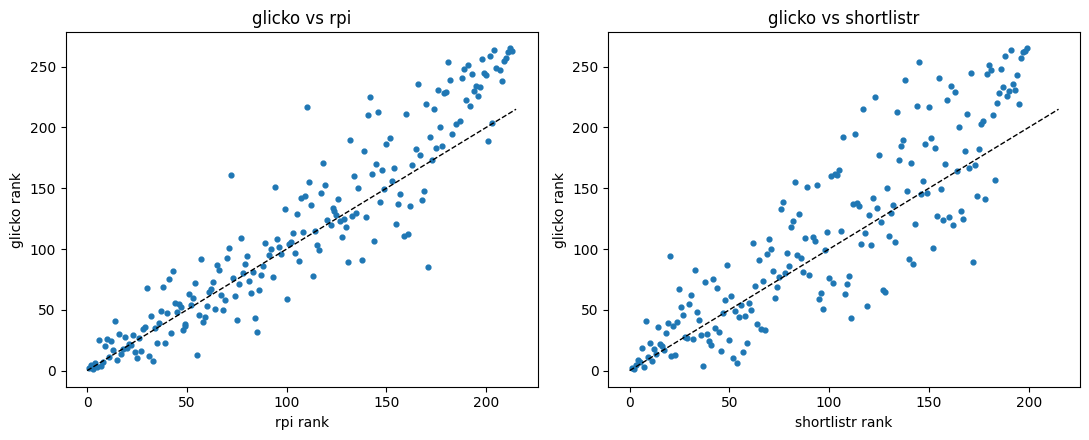

In [12]:
# Scatter: model rank vs reference rank
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, ref in zip(axes, REFS):
    out = tables[(ref, "glicko")].dropna(subset=["model_rank"])
    ax.scatter(out["rank"], out["model_rank"], s=12); ax.plot([0, 215], [0, 215], "k--", lw=1)
    ax.set_xlabel(f"{ref} rank"); ax.set_ylabel("glicko rank"); ax.set_title(f"glicko vs {ref}")
plt.tight_layout(); plt.show()

In [13]:
# Coaches' poll (top 25 only)
prow = []
for name in ["elo_xg", "glicko", "dixon_coles_xg"]:
    out, st = compare_poll("male", name, m_men); prow.append(st)
display(pd.DataFrame(prow).round(3))

,model,gender,teams_matched,n_ranked_teams,spearman,kendall,poll_top10_in_model_top10,poll_top25_in_model_top25,poll_top25_in_model_top50,median_model_rank_of_poll
0,elo_xg,male,25,265,0.664,0.491,6,17,24,16.0
1,glicko,male,25,265,0.700,0.544,6,21,25,16.0
2,dixon_coles_xg,male,25,265,0.696,0.531,5,15,24,17.0


## 6. Validation across many seasons (2021-2026)

`python -m ratings.history` walks each model through all matches and snapshots its team strengths at each reference's date
(so there is no look-ahead), then compares to: **Shortlistr** Team Strength (2023-26), **United Soccer Coaches** Week-11 poll
(last regular-season poll; Week 10 for 2026) and the post-tournament **Final** poll (2021-25), and the 2026 **NCAA RPI**.
Polls only cover 25 teams, so besides rank correlation we report how many poll teams the model also puts in its own top 25 / top 50.

In [14]:
hist = pd.read_csv(ROOT / "ratings" / "history_results.csv")
display(hist.pivot_table(index="model", columns=["ref", "year"], values="spearman").round(2))
display(hist.pivot_table(index="model", columns="ref", values="spearman").round(3).assign(
    overall=lambda d: d.mean(axis=1)).sort_values("overall", ascending=False))

ref                rpi shortlistr                   usc_final                         usc_wk11                              
year              2026       2023  2024  2025  2026      2021  2022  2023  2024  2025     2021  2022  2023  2024  2025  2026
model                                                                                                                       
dixon_coles       0.92       0.86  0.87  0.89  0.87      0.73  0.29  0.22  0.32  0.25     0.66  0.14  0.43  0.77  0.31  0.57
dixon_coles_xg    0.92       0.88  0.90  0.90  0.89      0.79  0.23  0.23  0.21  0.32     0.65  0.21  0.38  0.67  0.18  0.70
elo_none          0.93       0.85  0.91  0.91  0.87      0.77  0.65  0.64  0.60  0.54     0.66  0.26  0.55  0.77  0.67  0.61
elo_sqrt          0.93       0.88  0.93  0.93  0.90      0.84  0.67  0.67  0.54  0.58     0.65  0.29  0.52  0.88  0.74  0.67
elo_wfe_autocorr  0.93       0.87  0.91  0.91  0.88      0.85  0.66  0.65  0.47  0.47     0.66  0.26  0.53  0.81  0.72  0.55
elo_xg            0.91       0.91  0.93  0.93  0.91      0.81  0.58  0.38  0.28  0.42     0.68  0.26  0.37  0.74  0.35  0.66
ensemble_mean     0.94       0.89  0.92  0.92  0.90      0.88  0.64  0.47  0.42  0.46     0.70  0.35  0.48  0.83  0.54  0.70
ensemble_ols      0.92       0.89  0.91  0.91  0.91      0.83  0.42  0.31  0.22  0.35     0.66  0.25  0.42  0.68  0.24  0.70
glicko            0.94       0.87  0.90  0.91  0.88      0.73  0.60  0.57  0.34  0.46     0.70  0.40  0.65  0.70  0.70  0.70
pi                0.92       0.88  0.93  0.93  0.90      0.81  0.62  0.41  0.34  0.55     0.54  0.23  0.46  0.66  0.47  0.70
ridge_gd          0.92       0.89  0.90  0.92  0.90      0.88  0.47  0.34  0.26  0.47     0.62  0.39  0.33  0.61  0.39  0.47
ridge_gd_xg       0.90       0.84  0.85  0.85  0.85      0.84  0.27  0.40  0.02  0.35     0.57  0.26  0.40  0.49  0.12  0.60

ref,rpi,shortlistr,usc_final,usc_wk11,overall
model,,,,,
elo_sqrt,0.929,0.909,0.660,0.623,0.78025
elo_none,0.930,0.884,0.640,0.585,0.75975
elo_wfe_autocorr,0.926,0.891,0.620,0.588,0.75625
ensemble_mean,0.935,0.909,0.574,0.601,0.75475
glicko,0.943,0.889,0.539,0.643,0.75350
pi,0.917,0.910,0.546,0.511,0.72100
elo_xg,0.911,0.920,0.495,0.511,0.70925
ridge_gd,0.924,0.903,0.483,0.470,0.69500
ensemble_ols,0.920,0.904,0.428,0.491,0.68575


In [15]:
# Do polls' top-25 teams show up in our top 25 / top 50?
polls = hist[hist.ref.str.startswith("usc")]
display(polls.pivot_table(index="model", columns="ref", values="ref_top25_in_model_top25").round(1))
display(polls.pivot_table(index="model", columns="ref", values="ref_top25_in_model_top50").round(1))

ref,usc_final,usc_wk11
model,,
dixon_coles,18.2,17.7
dixon_coles_xg,18.2,17.5
elo_none,20.6,20.2
elo_sqrt,19.6,20.3
elo_wfe_autocorr,20.4,19.8
elo_xg,19.4,19.3
ensemble_mean,20.0,20.3
ensemble_ols,18.8,18.8
glicko,21.0,20.8


ref,usc_final,usc_wk11
model,,
dixon_coles,24.4,23.8
dixon_coles_xg,24.2,23.8
elo_none,24.8,24.8
elo_sqrt,24.4,24.8
elo_wfe_autocorr,24.4,24.5
elo_xg,24.2,24.5
ensemble_mean,25.0,24.8
ensemble_ols,24.6,24.3
glicko,24.8,25.0


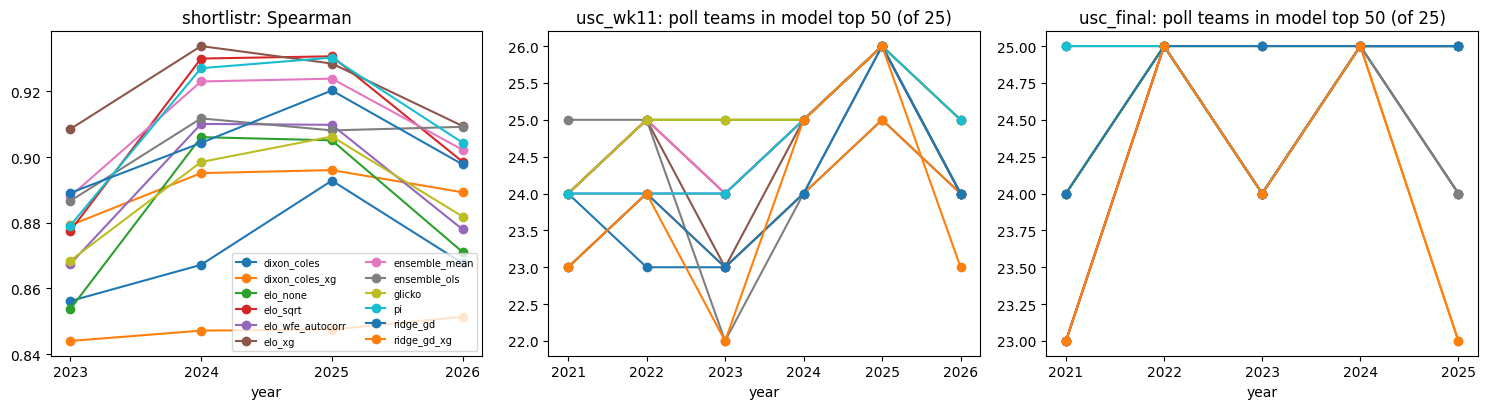

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=False)
for ax, ref in zip(axes, ["shortlistr", "usc_wk11", "usc_final"]):
    p = hist[hist.ref == ref].pivot_table(index="year", columns="model", values="ref_top25_in_model_top50" if ref.startswith("usc") else "spearman")
    p.plot(ax=ax, marker="o", legend=False)
    ax.set_title(f"{ref}: " + ("poll teams in model top 50 (of 25)" if ref.startswith("usc") else "Spearman")); ax.set_xticks(p.index)
axes[0].legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

## 7. Takeaways
Fill in after reviewing the tables above: which family wins, whether xG helps, and how much the ensemble adds over the best single model.
Next steps: model uncertainty via `Glicko.gap_sd`, conference-aware priors, and player/lineup-aware strength.